<div align="center">
    <img src="https://logoyab.com/wp-content/uploads/2024/08/IUST-University-Logo-1030x1030.png" alt="Logo" width="200">
    <p><b>Artificial Intelligence & Expert Systems </b></p>
    <p><b>Instructor: Dr. Arash Abdi</b></p>
</div>

--------


*Full Name:*

*Student Number:*

------

**Welcome to the ANN AI assignment!**

In this project, you will build a complete Multi-Layer Perceptron (MLP) framework from scratch using only NumPy. This project is divided into three main parts:

1.  **Part 1: MLP for Regression.** You will build all the core components of an MLP (Initialization, Forward Pass, MSE Loss, Backpropagation, and Training) to solve a regression task: **predicting song popularity** from a Spotify dataset.

2.  **Part 2: MLP for Classification.** You will **adapt** your regression framework to solve a multi-class classification task: recognizing handwritten digits from the famous **MNIST dataset**. This will require implementing a new activation function (Softmax) and a new loss function (Cross-Entropy).

3.  **Part 3: Analysis Laboratory.** You will use your **MNIST model** (from Part 2) to run a series of experiments. You will analyze the behavior of your model and compare different optimization techniques, activation functions, and hyperparameters, just as discussed in the lecture slides.

In [14]:
#DO NOT IMPORT ANY OTHER LIBRARY
#Run these cells as they are
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import math
from tqdm import tqdm
from copy import deepcopy
import seaborn as sns

# required only for jupyter notebooks / while running on colab
%matplotlib inline

# set seed
seed = 42
np.random.seed(seed)

# Part 1 - MLP for Regression (Spotify Song Popularity)

In this part, we will build a **4-layer** MLP to predict song popularity.

## 1.1 Data Loading and Preprocessing

Our goal is to predict a song's **`popularity`** (a score from 0-100) based on its audio features like `danceability`, `energy`, `loudness`, etc. 

We will load the data, select only the numerical features, and scale them to a [0, 1] range using `MinMaxScaler`.

In [15]:
# Load the dataset
try:
    spotify_df = pd.read_csv('tracks.csv')
    
    # The tracks.csv has 'release_date', so we create 'year' from it
    if 'year' not in spotify_df.columns and 'release_date' in spotify_df.columns:
        spotify_df['year'] = pd.to_datetime(spotify_df['release_date'], errors='coerce').dt.year
    # -------------------------------------

except FileNotFoundError:
    print("ERROR: 'tracks.csv' not found.")
    print("Please download it from Kaggle: https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks")
    print("Generating dummy data for testing...")
    spotify_df = pd.DataFrame(np.random.rand(100, 14), 
                              columns=['acousticness', 'danceability', 'energy', 'instrumentalness', 
                                       'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 
                                       'key', 'mode', 'explicit', 'year'])

# Select features (X) and target (Y)
features = ['acousticness', 'danceability', 'energy', 'instrumentalness', 
            'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 
            'key', 'mode', 'explicit', 'year']
target = 'popularity'

# Drop NAs
spotify_df = spotify_df.dropna(subset=features + [target])

# Ensure numeric types
for col in features + [target]:
    spotify_df[col] = pd.to_numeric(spotify_df[col], errors='coerce')
    
spotify_df = spotify_df.dropna()

# For performance, we'll sample 30,000 tracks
if len(spotify_df) > 30000:
    spotify_df = spotify_df.sample(n=30000, random_state=seed)

X_spotify = spotify_df[features]
Y_spotify = spotify_df[[target]]

# Scale the data
scaler_X = MinMaxScaler()
scaler_Y = MinMaxScaler()
X_spotify_scaled = scaler_X.fit_transform(X_spotify)
Y_spotify_scaled = scaler_Y.fit_transform(Y_spotify)

# Split data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_spotify_scaled, Y_spotify_scaled, test_size=0.2, random_state=seed)

# Transpose for our NN architecture: (features, num_examples)
x_train_reg = X_train_reg.T
y_train_reg = y_train_reg.T
x_test_reg = X_test_reg.T
y_test_reg = y_test_reg.T

print(f"X_train_reg shape: {x_train_reg.shape}")
print(f"y_train_reg shape: {y_train_reg.shape}")
print(f"(Input features, 'I' = {x_train_reg.shape[0]})")

X_train_reg shape: (13, 24000)
y_train_reg shape: (1, 24000)
(Input features, 'I' = 13)


## 1.2 MLP Architecture

We will implement a **four-layer fully-connected neural network**.

**Architecture:** `input - FC - ReLU - FC - ReLU - FC - ReLU - FC - Output`

The output activation is also ReLU (for Regression) to ensure our prediction `popularity` is non-negative.

**Dimensions (Example):**
* `I`: Input features (13 for Spotify)
* `H1`: 64 neurons
* `H2`: 32 neurons
* `H3`: 16 neurons
* `O`: Output Layer (1 for this regression task)

## 1.3 Helper: Parameter Initialization (He Initialization)

**NOTE: This function is already implemented for you.**

To ensure the network learns effectively using ReLU activations, we must initialize weights carefully. If weights are too small, gradients vanish. If too large, they explode.

We use **He Initialization**:
$$W^{[l]} \sim \mathcal{N}(0, \frac{2}{n^{[l-1]}})$$

You will simply **run this cell** to define the initialization function. Later in **Part 3**, you will analyze what happens if we don't use this method.

In [16]:
def Initialization(I, H1, H2, H3, O):
    '''
    Initializes weights using He Initialization (optimized for ReLU).
    
    Inputs:
        I, H1, H2, H3, O: Number of neurons in each layer.
        
    Returns:
        List of parameters: [W1, b1, W2, b2, W3, b3, W4, b4]
    '''
    np.random.seed(42) # Ensure reproducibility

    # Calculate scaling factors for He Initialization
    scale1 = np.sqrt(2.0 / I)
    scale2 = np.sqrt(2.0 / H1)
    scale3 = np.sqrt(2.0 / H2)
    scale4 = np.sqrt(2.0 / H3)
    
    # Layer 1: Input -> Hidden 1
    W1 = np.random.randn(H1, I) * scale1
    b1 = np.zeros((H1, 1))
    
    # Layer 2: Hidden 1 -> Hidden 2
    W2 = np.random.randn(H2, H1) * scale2
    b2 = np.zeros((H2, 1))
    
    # Layer 3: Hidden 2 -> Hidden 3
    W3 = np.random.randn(H3, H2) * scale3
    b3 = np.zeros((H3, 1))
    
    # Layer 4: Hidden 3 -> Output
    W4 = np.random.randn(O, H3) * scale4
    b4 = np.zeros((O, 1))
    
    print("Parameters initialized with He Initialization.")
    return [W1, b1, W2, b2, W3, b3, W4, b4]

In [17]:
#Sample test case
np.random.seed(seed)
params_list = Initialization(13, 64, 32, 16, 1)
assert len(params_list) == 8
assert params_list[0].shape == (64, 13) 
assert params_list[1].shape == (64, 1)  
assert params_list[6].shape == (1, 16)  
assert np.mean(params_list[0]) < 0.1 and np.mean(params_list[0]) > -0.1
print('Sample Test passed', '\U0001F44D')

Parameters initialized with He Initialization.
Sample Test passed 👍


## 1.4 Task: Activation Function (ReLU)

Implement the ReLU activation function and its derivative.

$$\text{ReLU}(z) = \max(0, z)$$

$$\frac{\partial \text{ReLU}(z)}{\partial z} = \begin{cases} 1 & z > 0 \\ 0 & z \le 0 \end{cases}$$

In [18]:
def relu(x):
    return np.maximum(0, x)

def drelu(x):
    return (x > 0).astype(float)

In [19]:
# sample test case
x_sample = np.array([[3, -4], [0, -0.5]])
assert np.allclose(relu(x_sample), np.array([[3, 0], [0, 0]]))
assert np.allclose(drelu(x_sample), np.array([[1, 0], [0, 0]]))
print('Sample Test passed', '\U0001F44D')

Sample Test passed 👍


## 1.5 Task: Forward Propagation

Implement the forward pass for the **4-layer** network.

**Formulas:**

$$Z^{[h]} = W^{[h]} \cdot A^{[h-1]} + b^{[h]}$$

$$A^{[h]} = \text{ReLU}(Z^{[h]})$$

* Use **ReLU** for *all* layers (A1, A2, A3, and A4).
* $A^{[0]} = X$

In [20]:
import numpy as np

def feed_forward(X, params):
    '''
    Inputs:
    - X : Input data of shape (I, num_examples)
    - params: List of parameters [W1, b1, W2, b2, W3, b3, W4, b4]

    Outputs:
    - y_out : predicted output (A4), shape (O, num_examples)
    - cache : List containing [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
    '''
    W1, b1, W2, b2, W3, b3, W4, b4 = params
    cache = []
    A0 = X

    # START TODO ################ (approx. 12 lines)
    Z1 = W1 @ A0 + b1
    A1 = relu(Z1)

    Z2 = W2 @ A1 + b2
    A2 = relu(Z2)

    Z3 = W3 @ A2 + b3
    A3 = relu(Z3)

    Z4 = W4 @ A3 + b4
    A4 = relu(Z4)

    cache = [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
    # END TODO ###################

    y_out = A4
    return y_out, cache


In [21]:
#Sample test case
np.random.seed(seed)
I, H1, H2, H3, O, m = 13, 64, 32, 16, 1, 100
params_list = Initialization(I, H1, H2, H3, O)
X_sample = np.random.rand(I, m)
y_forward, cache = feed_forward(X_sample, params_list)

assert y_forward.shape == (O, m)
assert len(cache) == 8 
assert cache[0].shape == (H1, m) 
assert cache[7].shape == (O, m) 
print('Sample Test passed', '\U0001F44D')

Parameters initialized with He Initialization.
Sample Test passed 👍


## 1.6 Task: Loss Function (MSE)

Implement the Mean Squared Error (MSE) loss.

$$L = \frac{1}{2m} \sum_{i=1}^{m} (y_d^{(i)} - y_{pred}^{(i)})^2$$

Where `m` is the number of examples.

In [22]:
def loss_compute(y_pred, yd):
    '''
    Inputs:
    - y_pred: (O, m) numpy array of predicted values
    - yd: (O, m) numpy array of true values

    Outputs:
    - loss: The MSE Loss (scalar)
    '''
    m = yd.shape[1]

    # START TODO ################ (approx. 2 lines)
    loss = (1 / (2 * m)) * np.sum((yd - y_pred) ** 2)
    # END TODO ###################

    return loss


In [23]:
sample_loss = loss_compute(np.array([[1, 1, 4]]), np.array([[1, 0, 2]]))
assert np.allclose(sample_loss, 0.8333333333333334)
print('Sample Test passed', '\U0001F44D')

Sample Test passed 👍


## 1.7 Task: L2 Regularization

Implement the L2 regularization cost.

$$L_{reg} = \frac{1}{m} \frac{\lambda}{2} \sum_{l=1}^{L} \|W^{[l]}\|^2_F$$

Where $L=4$ layers, $\lambda$ is the regularization parameter, `m` is the number of examples.

In [24]:
def regularization_L2(lmbda, W1, W2, W3, W4, m):
    '''
    Inputs:
    - lmbda: Regularization parameter (lambda)
    - W1, W2, W3, W4: Weight matrices
    - m: number of examples

    Outputs:
    - reg_loss: The L2 regularization cost (scalar)
    '''

    # START TODO ################ (approx. 2 lines)
    reg_loss = (lmbda / (2 * m)) * (
        np.sum(W1**2) + np.sum(W2**2) + np.sum(W3**2) + np.sum(W4**2)
    )
    # END TODO ###################

    return reg_loss


In [25]:
# TEST CASE 1
w1 = np.array([[1, 1], [1, 1]])
w2 = np.array([[1, 1], [1, 1]])
w3, w4 = w1.copy(), w2.copy()
assert np.allclose(regularization_L2(0.1, w1, w2, w3, w4, 2), 0.4)
print('Sample Test passed', '\U0001F44D')

Sample Test passed 👍


## 1.8 Task: Backpropagation

Now, implement the backward pass for the **4-layer** network.

**Key Formulas (for Regression):**

1.  **Start at Layer 4 (Output):**

$$dA^{[4]} = \frac{\partial L}{\partial A^{[4]}} = \frac{1}{m} (A^{[4]} - Y)$$

2.  **Propagate through Layer $h$:**

$$dZ^{[h]} = dA^{[h]} * g'^{[h]}(Z^{[h]})$$

(where $g'$ is `drelu` for all layers in this part)

$$dW^{[h]} = dZ^{[h]} \cdot A^{[h-1]T} + \frac{\lambda}{m} W^{[h]}$$

$$db^{[h]} = \sum_{i=1}^{m} dZ^{[h](i)} \text{ (axis=1, keepdims=True)}$$

$$dA^{[h-1]} = W^{[h]T} \cdot dZ^{[h]}$$

You can implement the backprop logic directly in the `Backpropagation_reg` function or make a helper.

In [26]:
def Backpropagation_reg(X, yd, cache, parameters, lmbda):
    '''
    Performs the backward pass for the 4-layer network (Regression version).

    Inputs:
    - X: Input features (I, m)
    - yd: True labels (O, m)
    - cache: List from feed_forward [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
    - parameters: List of parameters [W1, b1, W2, b2, W3, b3, W4, b4]
    - lmbda: regularization parameter

    Outputs:
    - grads: Dictionary of gradients { "dW1": dW1, "db1": db1, ... }
    '''
    m = X.shape[1]
    W1, b1, W2, b2, W3, b3, W4, b4 = parameters
    Z1, A1, Z2, A2, Z3, A3, Z4, A4 = cache
    grads = {}

    # START TODO ################ (approx. 15 lines)

    # Layer 4
    dA4 = (1 / m) * (A4 - yd)
    dZ4 = dA4 * drelu(Z4)
    dW4 = dZ4 @ A3.T + (lmbda / m) * W4
    db4 = np.sum(dZ4, axis=1, keepdims=True)
    dA3 = W4.T @ dZ4

    # Layer 3
    dZ3 = dA3 * drelu(Z3)
    dW3 = dZ3 @ A2.T + (lmbda / m) * W3
    db3 = np.sum(dZ3, axis=1, keepdims=True)
    dA2 = W3.T @ dZ3

    # Layer 2
    dZ2 = dA2 * drelu(Z2)
    dW2 = dZ2 @ A1.T + (lmbda / m) * W2
    db2 = np.sum(dZ2, axis=1, keepdims=True)
    dA1 = W2.T @ dZ2

    # Layer 1
    dZ1 = dA1 * drelu(Z1)
    dW1 = dZ1 @ X.T + (lmbda / m) * W1
    db1 = np.sum(dZ1, axis=1, keepdims=True)

    grads["dW1"], grads["db1"] = dW1, db1
    grads["dW2"], grads["db2"] = dW2, db2
    grads["dW3"], grads["db3"] = dW3, db3
    grads["dW4"], grads["db4"] = dW4, db4

    # END TODO ###################

    return grads


In [27]:
#Sample test case
np.random.seed(seed)
I, H1, H2, H3, O, m = 13, 64, 32, 16, 1, 100
params_list = Initialization(I, H1, H2, H3, O)
X_sample = np.random.rand(I, m)
Y_sample = np.random.rand(O, m)
y_forward, cache = feed_forward(X_sample, params_list)
grads = Backpropagation_reg(X_sample, Y_sample, cache, params_list, lmbda=0.1)

assert grads['dW1'].shape == (H1, I)
assert grads['db1'].shape == (H1, 1)
assert grads['dW4'].shape == (O, H3)
assert grads['db4'].shape == (O, 1)
print('Sample Test passed', '\U0001F44D')

Parameters initialized with He Initialization.
Sample Test passed 👍


## 1.9 Task: Training the Model (Regression)

Combine all the functions to train the model. 

**Steps for each iteration:**
1.  Perform a `feed_forward` pass to get $y_{pred}$ and the `cache`.
2.  Compute the `loss` (MSE) using $y_{pred}$ and $y_d$.
3.  Compute the `reg_loss` (L2) using the weights.
4.  Calculate the `total_loss = loss + reg_loss` and store it.
5.  Perform `Backpropagation_reg` to get the `grads`.
6.  Update all parameters ($W$ and $b$) using gradient descent:

$$
\begin{aligned}
W^{[h]} &= W^{[h]} - \eta \cdot dW^{[h]} \\
b^{[h]} &= b^{[h]} - \eta \cdot db^{[h]}
\end{aligned}
$$

In [28]:
def training_reg(X, yd, parameters, eta = 0.05, num_iters=3000, lmbda = 0.1):
    '''
      Inputs:
      - X: Input features (I, m)
      - yd: True labels (O, m)
      - parameters: Initialized parameters list
      - eta: learning rate
      - num_iters: number of iterations
      - lmbda: regularization parameter

      Outputs:
      - losses: list of total loss at each iteration
      - parameters: the final trained parameters list
    '''
    losses = []
    m = X.shape[1]
    
    W1, b1, W2, b2, W3, b3, W4, b4 = parameters

    for i in tqdm(range(num_iters)):
        # START TODO ################ (approx. 15-20 lines)

        # 1) Forward
        y_pred, cache = feed_forward(X, [W1, b1, W2, b2, W3, b3, W4, b4])

        # 2) Data loss (MSE)
        loss = loss_compute(y_pred, yd)

        # 3) Regularization loss (L2)
        reg_loss = regularization_L2(lmbda, W1, W2, W3, W4, m)

        # 4) Total loss
        total_loss = loss + reg_loss
        losses.append(total_loss)

        # 5) Backprop
        grads = Backpropagation_reg(X, yd, cache, [W1, b1, W2, b2, W3, b3, W4, b4], lmbda)

        # 6) Gradient descent update
        W1 = W1 - eta * grads["dW1"]
        b1 = b1 - eta * grads["db1"]
        W2 = W2 - eta * grads["dW2"]
        b2 = b2 - eta * grads["db2"]
        W3 = W3 - eta * grads["dW3"]
        b3 = b3 - eta * grads["db3"]
        W4 = W4 - eta * grads["dW4"]
        b4 = b4 - eta * grads["db4"]

        # END TODO ###################

    parameters_final = [W1, b1, W2, b2, W3, b3, W4, b4]
    return losses, parameters_final


Parameters initialized with He Initialization.


100%|██████████| 300/300 [00:11<00:00, 27.14it/s]


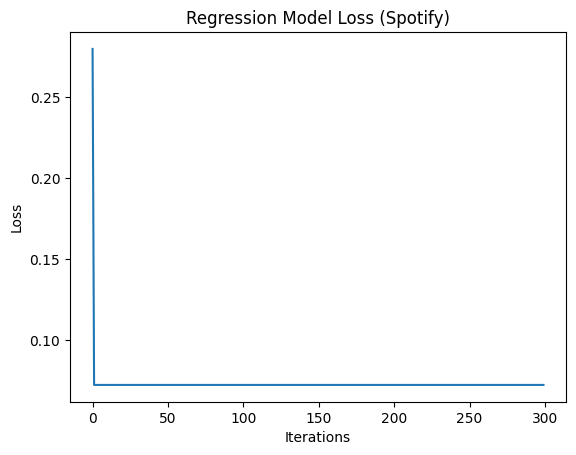

In [31]:
I = x_train_reg.shape[0]
O = y_train_reg.shape[0]
H1, H2, H3 = 64, 32, 16

np.random.seed(seed)
init_params_reg = Initialization(I, H1, H2, H3, O)

# 300 iterations is just for testing. For a good result, try 3000-5000.
losses_reg, params_reg = training_reg(x_train_reg, y_train_reg, init_params_reg, eta=0.05, num_iters=300, lmbda=0.01)

plt.plot(losses_reg)
plt.ylabel('Loss')
plt.xlabel('Iterations')
plt.title('Regression Model Loss (Spotify)')
plt.show()

In [30]:
#Sample test case
y_pred_test_reg, _ = feed_forward(x_test_reg, params_reg)
test_loss = loss_compute(y_pred_test_reg, y_test_reg)
print(f"Final Test MSE (Spotify): {test_loss}")

assert losses_reg[-1] < losses_reg[0], "Loss should decrease!"
print('Sample Test passed', '\U0001F44D')

Final Test MSE (Spotify): 0.07102153237240075
Sample Test passed 👍


# Part 2 - MLP for Classification (MNIST)

Now, we adapt our framework for MNIST. This requires key changes:
1.  **Output Layer:** 10 neurons (one for each digit 0-9).
2.  **Output Activation:** **Softmax** (to get probabilities for each class).
3.  **Loss Function:** **Cross-Entropy Loss** (standard for multi-class classification).
4.  **Backpropagation:** The initial gradient ($dA^{[4]}$) changes due to the new loss function.

## 2.1 Data Loading and Preprocessing (MNIST)

We load MNIST. X is flattened to (784, 60000) and scaled. Y is One-Hot Encoded to (10, 60000).

In [32]:
# Load MNIST data
X_mnist, y_mnist = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='auto')

# --- Preprocessing --- 

# 1. Scale X (pixels) from 0-255 to 0-1
X_mnist_scaled = X_mnist / 255.0

# 2. One-Hot Encode Y (labels)
# Convert '0'-'9' strings to integers
y_mnist_int = y_mnist.astype(int)
# Reshape to (m, 1) for the encoder
y_mnist_reshaped = y_mnist_int.reshape(-1, 1)
# Apply OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, categories='auto')
Y_mnist_onehot = encoder.fit_transform(y_mnist_reshaped)

# 3. Split data
# MNIST is already split, but we'll shuffle and split for a test set
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_mnist_scaled, Y_mnist_onehot, test_size=0.15, random_state=seed)

# 4. Transpose for our NN architecture: (features, num_examples)
x_train_clf = X_train_clf.T
y_train_clf = y_train_clf.T
x_test_clf = X_test_clf.T
y_test_clf = y_test_clf.T

print(f"X_train_clf shape: {x_train_clf.shape}")
print(f"y_train_clf shape: {y_train_clf.shape}")
print(f"X_test_clf shape: {x_test_clf.shape}")
print(f"y_test_clf shape: {y_test_clf.shape}")

X_train_clf shape: (784, 59500)
y_train_clf shape: (10, 59500)
X_test_clf shape: (784, 10500)
y_test_clf shape: (10, 10500)


## 2.1 Task: Softmax Activation

Implement the softmax function. This converts raw scores (logits) into probabilities.

$$\text{softmax}(Z)_i = \frac{e^{Z_i}}{\sum_{j} e^{Z_j}}$$

**Hint:** Use the stabilization trick: `exp(Z - np.max(Z))` to prevent overflow.

In [ ]:
def softmax(Z):
    '''
    Computes softmax for each column of Z.
    Input:
    - Z: (O, m) array of logits
    Output:
    - A: (O, m) array of probabilities
    '''

    # START TODO ################ (approx. 2 lines)
    Z_shifted = Z - np.max(Z, axis=0, keepdims=True)
    exp_Z = np.exp(Z_shifted)
    A = exp_Z / np.sum(exp_Z, axis=0, keepdims=True)
    # END TODO ###################

    return A



In [34]:
# Sample test case
Z_sample = np.array([[1, 2], [1, 3], [1, 1]])
A_sample = softmax(Z_sample)
assert A_sample.shape == (3, 2)
assert np.allclose(np.sum(A_sample, axis=0), np.array([1.0, 1.0]))
assert np.allclose(A_sample[0, 0], 0.33333333)
assert np.allclose(A_sample[1, 1], 0.66524096)
print('Sample Test passed', '\U0001F44D')

Sample Test passed 👍


## 2.2 Task: Cross-Entropy Loss

Implement the cross-entropy loss function.

$$L = -\frac{1}{m} \sum_{i=1}^{m} \sum_{j=1}^{O} Y_j^{(i)} \log(A_j^{[L](i)})$$

Where $Y$ is the one-hot true label and $A^{[L]}$ is the softmax output (prediction).

In [35]:
def cross_entropy_loss(y_pred, yd):
    '''
    Computes the cross-entropy loss.
    Inputs:
    - y_pred: (O, m) array of predicted probabilities (A4)
    - yd: (O, m) array of true one-hot labels (Y)

    Output:
    - loss: The cross-entropy loss (scalar)
    '''
    m = yd.shape[1]
    epsilon = 1e-8  # to avoid log(0)

    # START TODO ################ (approx. 2 lines)
    loss = - (1 / m) * np.sum(yd * np.log(y_pred + epsilon))
    # END TODO ###################

    return loss


In [36]:
# Sample test case
y_pred_sample = np.array([[0.1, 0.8], [0.1, 0.1], [0.8, 0.1]])
y_true_sample = np.array([[0, 1], [0, 0], [1, 0]])
loss_sample = cross_entropy_loss(y_pred_sample, y_true_sample)
assert np.allclose(loss_sample, 0.2231435513142097)
print('Sample Test passed', '\U0001F44D')

Sample Test passed 👍


## 2.3 Task: Forward Propagation (Classification)

Copy your `feed_forward` function from Part 1 and modify it for classification.

**Changes:**
* Layers 1-3 (Z1-A3): Still use **ReLU**.
* Layer 4 (Z4, A4): The output layer $A^{[4]}$ must now use **Softmax**.

In [37]:
def feed_forward_clf(X, params):
    '''
    Forward pass for classification.
    g is ReLU for A1-A3. g' is Softmax for A4.

    Outputs:
    - y_out : predicted output (A4), shape (O, num_examples)
    - cache : List containing [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
    '''
    W1, b1, W2, b2, W3, b3, W4, b4 = params
    cache = []
    A0 = X

    # START TODO ################ (approx. 10 lines )
    Z1 = W1 @ A0 + b1
    A1 = relu(Z1)

    Z2 = W2 @ A1 + b2
    A2 = relu(Z2)

    Z3 = W3 @ A2 + b3
    A3 = relu(Z3)

    Z4 = W4 @ A3 + b4
    A4 = softmax(Z4)

    cache = [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
    # END TODO ###################

    y_out = A4
    return y_out, cache


In [38]:
#Sample test case
np.random.seed(seed)
I, H1, H2, H3, O, m = 784, 64, 32, 16, 10, 100
params_list_clf = Initialization(I, H1, H2, H3, O)
X_sample_clf = np.random.rand(I, m)
y_forward_clf, cache_clf = feed_forward_clf(X_sample_clf, params_list_clf)

assert y_forward_clf.shape == (O, m)
assert len(cache_clf) == 8
assert cache_clf[7].shape == (O, m)  # A4
assert np.allclose(np.sum(y_forward_clf, axis=0), 1.0)
print('Sample Test passed', '\U0001F44D')

Parameters initialized with He Initialization.
Sample Test passed 👍


## 2.4 Task: Backpropagation (Classification)

Implement the backward pass for the classification network.

**Key Formula Change:**

The gradient calculation for the **last layer (Layer 4)** is different. The derivative of Cross-Entropy Loss with respect to the pre-activation $Z^{[4]}$ (before Softmax) simplifies nicely:

$$dZ^{[4]} = \frac{\partial L}{\partial Z^{[4]}} = \frac{1}{m} (A^{[4]} - Y)$$

For all other layers (1-3), the formulas remain the same as in regression, using `drelu`.

In [39]:
def Backpropagation_clf(X, yd, cache, parameters, lmbda):
    '''
    Performs the backward pass for the 4-layer network (Classification version).
    Inputs:
    - X: (I, m)
    - yd: (O, m) one-hot labels
    - cache: [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
    - parameters: [W1, b1, W2, b2, W3, b3, W4, b4]
    - lmbda: regularization parameter

    Outputs:
    - grads: dict of gradients
    '''
    m = X.shape[1]
    W1, b1, W2, b2, W3, b3, W4, b4 = parameters
    Z1, A1, Z2, A2, Z3, A3, Z4, A4 = cache
    grads = {}

    # START TODO ################ (approx. 13 lines)

    # Layer 4 (Softmax + Cross-Entropy)
    dZ4 = (1 / m) * (A4 - yd)
    dW4 = dZ4 @ A3.T + (lmbda / m) * W4
    db4 = np.sum(dZ4, axis=1, keepdims=True)
    dA3 = W4.T @ dZ4

    # Layer 3 (ReLU)
    dZ3 = dA3 * drelu(Z3)
    dW3 = dZ3 @ A2.T + (lmbda / m) * W3
    db3 = np.sum(dZ3, axis=1, keepdims=True)
    dA2 = W3.T @ dZ3

    # Layer 2 (ReLU)
    dZ2 = dA2 * drelu(Z2)
    dW2 = dZ2 @ A1.T + (lmbda / m) * W2
    db2 = np.sum(dZ2, axis=1, keepdims=True)
    dA1 = W2.T @ dZ2

    # Layer 1 (ReLU)
    dZ1 = dA1 * drelu(Z1)
    dW1 = dZ1 @ X.T + (lmbda / m) * W1
    db1 = np.sum(dZ1, axis=1, keepdims=True)

    grads["dW1"], grads["db1"] = dW1, db1
    grads["dW2"], grads["db2"] = dW2, db2
    grads["dW3"], grads["db3"] = dW3, db3
    grads["dW4"], grads["db4"] = dW4, db4

    # END TODO ###################

    return grads


In [40]:
#Sample test case
np.random.seed(seed)
I, H1, H2, H3, O, m = 784, 64, 32, 16, 10, 100
params_list_clf = Initialization(I, H1, H2, H3, O)
X_sample_clf = np.random.rand(I, m)
Y_sample_clf = np.eye(O)[np.random.choice(O, m)].T 
y_forward_clf, cache_clf = feed_forward_clf(X_sample_clf, params_list_clf)
grads = Backpropagation_clf(X_sample_clf, Y_sample_clf, cache_clf, params_list_clf, lmbda=0.1)

assert grads['dW1'].shape == (H1, I)
assert grads['db1'].shape == (H1, 1)
assert grads['dW4'].shape == (O, H3)
assert grads['db4'].shape == (O, 1)
print('Sample Test passed', '\U0001F44D')

Parameters initialized with He Initialization.
Sample Test passed 👍


## 2.5 Task: Training the Model (Classification)

Adapt your `training_reg` function to create `training_clf`.

**Changes:**
1.  Use `feed_forward_clf` (with Softmax).
2.  Use `cross_entropy_loss`.
3.  Use `Backpropagation_clf` (with Softmax/CE derivative).
4.  (Optional) Track and print `accuracy` in addition to loss.

In [41]:
def training_clf(X, yd, parameters, eta = 0.05, num_iters=3000, lmbda = 0.1):
    '''
    Trains the classification model.
    '''
    losses = []
    accuracies = []
    m = X.shape[1]

    W1, b1, W2, b2, W3, b3, W4, b4 = parameters

    for i in tqdm(range(num_iters)):
        # START TODO ################ (approx. 18 lines )

        # 1) Forward (softmax output)
        y_pred, cache = feed_forward_clf(X, [W1, b1, W2, b2, W3, b3, W4, b4])

        # 2) Data loss (Cross-Entropy)
        loss = cross_entropy_loss(y_pred, yd)

        # 3) Regularization loss (L2)
        reg_loss = regularization_L2(lmbda, W1, W2, W3, W4, m)

        # 4) Total loss
        total_loss = loss + reg_loss
        losses.append(total_loss)

        # 5) Backprop
        grads = Backpropagation_clf(X, yd, cache, [W1, b1, W2, b2, W3, b3, W4, b4], lmbda)

        # 6) Update params
        W1 = W1 - eta * grads["dW1"]
        b1 = b1 - eta * grads["db1"]
        W2 = W2 - eta * grads["dW2"]
        b2 = b2 - eta * grads["db2"]
        W3 = W3 - eta * grads["dW3"]
        b3 = b3 - eta * grads["db3"]
        W4 = W4 - eta * grads["dW4"]
        b4 = b4 - eta * grads["db4"]

        # END TODO ###################

        if i % 100 == 0:
            predictions = np.argmax(y_pred, axis=0)
            true_labels = np.argmax(yd, axis=0)
            acc = accuracy_score(true_labels, predictions)
            accuracies.append(acc)

    parameters_final = [W1, b1, W2, b2, W3, b3, W4, b4]
    return losses, accuracies, parameters_final


Parameters initialized with He Initialization.


100%|██████████| 1500/1500 [00:26<00:00, 57.36it/s]


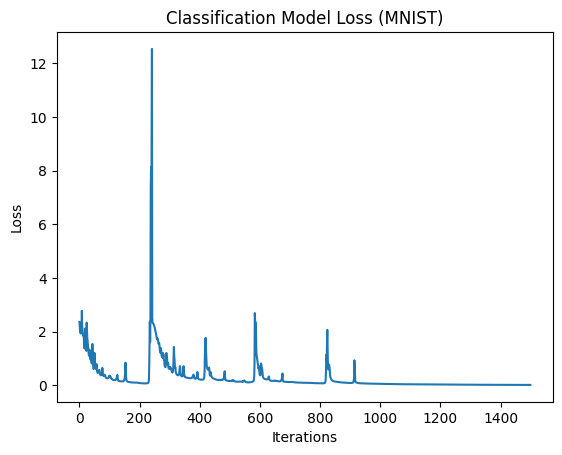

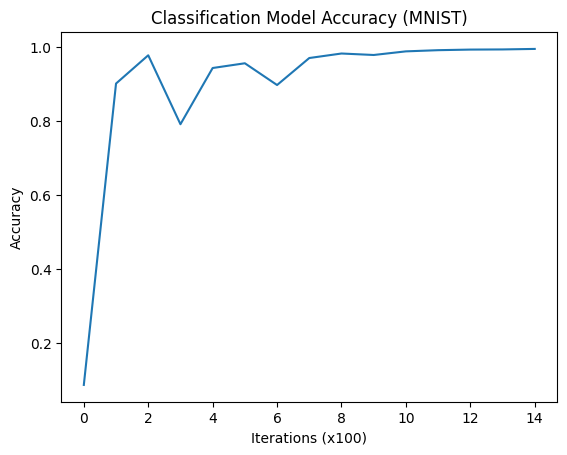

In [42]:
I_clf = x_train_clf.shape[0] 
O_clf = y_train_clf.shape[0] 
H1, H2, H3 = 64, 32, 16 

np.random.seed(seed)
init_params_clf = Initialization(I_clf, H1, H2, H3, O_clf)

# Train the model (using a small subset for speed in the test case)
m_sample = 5000
X_sample_train = x_train_clf[:, :m_sample]
y_sample_train = y_train_clf[:, :m_sample]



losses_clf, accuracies_clf, params_clf = training_clf(
    X_sample_train, 
    y_sample_train, 
    init_params_clf, 
    eta=0.5,         
    num_iters=1500,  
    lmbda=0.0       
)
plt.plot(losses_clf)
plt.ylabel('Loss')
plt.xlabel('Iterations')
plt.title('Classification Model Loss (MNIST)')
plt.show()

plt.plot(accuracies_clf)
plt.ylabel('Accuracy')
plt.xlabel('Iterations (x100)')
plt.title('Classification Model Accuracy (MNIST)')
plt.show()

In [43]:
#Sample test case
assert losses_clf[-1] < losses_clf[0]
print('Sample Test passed', '\U0001F44D')

y_pred_test_clf, _ = feed_forward_clf(x_test_clf, params_clf)
predictions_test = np.argmax(y_pred_test_clf, axis=0)
true_labels_test = np.argmax(y_test_clf, axis=0)
test_acc = accuracy_score(true_labels_test, predictions_test)
print(f"Final Test Accuracy (MNIST): {test_acc * 100:.2f}%")

Sample Test passed 👍
Final Test Accuracy (MNIST): 90.92%


# Part 3 - Analysis Laboratory (on MNIST)

Now, use your **MNIST classification model** from Part 2 to perform the following analyses. You will submit these plots and your written answers in your final report.

## 3.1 Analysis: SGD vs. Batch Gradient Descent

The `training_clf` function you wrote implements **Batch Gradient Descent** (it computes the gradient using *all* `m` samples at once). 

**Your Task:**
1.  Create a new function `training_clf_sgd` that performs **Stochastic Gradient Descent (SGD)**. In SGD, the loop iterates over *each individual training sample* (m=1) one by one, performing a forward pass, backward pass, and parameter update for each one.
2.  Train two models on the *same* training data (e.g., first 2000 samples for 5 epochs).
3.  **Plot:** Plot the loss curves for both models on the *same* graph.
4.  **Analyze:** In your report, answer:
    * Which loss curve is "noisier"? Why?
    * Which method converged faster in terms of epochs? 

In [44]:
def training_clf_sgd(X, yd, parameters, eta=0.05, num_epochs=5, lmbda=0.1):
    '''
    Trains the classification model using SGD (4-layer version).
    Iterate one sample at a time.
    '''
    epoch_losses = []
    m = X.shape[1]
    
    # Unpack 4 layers
    W1, b1, W2, b2, W3, b3, W4, b4 = parameters

    for epoch in tqdm(range(num_epochs)):
        epoch_loss_sum = 0
        
        # Shuffle data for each epoch
        permutation = np.random.permutation(m)
        X_shuffled = X[:, permutation]
        y_shuffled = yd[:, permutation]
        
        # Limit to 2000 samples for speed in this assignment context
        limit = min(m, 2000)

        for i in range(limit):
            # Get a single sample (m=1)
            Xi = X_shuffled[:, i:i+1]
            yi = y_shuffled[:, i:i+1]

            # START TODO ################

            # 1) Forward (softmax output)
            y_pred, cache = feed_forward_clf(Xi, [W1, b1, W2, b2, W3, b3, W4, b4])

            # 2) Data loss (Cross-Entropy) for this single sample
            loss = cross_entropy_loss(y_pred, yi)

            # 3) Regularization loss (L2) -- here batch size is 1
            reg_loss = regularization_L2(lmbda, W1, W2, W3, W4, m=1)

            # 4) Total loss accumulate for epoch average
            total_loss = loss + reg_loss
            epoch_loss_sum += total_loss

            # 5) Backprop (m=1 inside because Xi has one column)
            grads = Backpropagation_clf(
                Xi, yi, cache,
                [W1, b1, W2, b2, W3, b3, W4, b4],
                lmbda
            )

            # 6) Update parameters immediately (SGD step)
            W1 = W1 - eta * grads["dW1"]
            b1 = b1 - eta * grads["db1"]
            W2 = W2 - eta * grads["dW2"]
            b2 = b2 - eta * grads["db2"]
            W3 = W3 - eta * grads["dW3"]
            b3 = b3 - eta * grads["db3"]
            W4 = W4 - eta * grads["dW4"]
            b4 = b4 - eta * grads["db4"]

            # END TODO ###################
        
        # Average loss for the processed samples
        epoch_losses.append(epoch_loss_sum / limit)

    parameters_final = [W1, b1, W2, b2, W3, b3, W4, b4]
    return epoch_losses, parameters_final


Running Batch Gradient Descent...
Parameters initialized with He Initialization.


100%|██████████| 5/5 [00:00<00:00, 32.96it/s]


Running Stochastic Gradient Descent...
Parameters initialized with He Initialization.


100%|██████████| 5/5 [00:02<00:00,  2.23it/s]


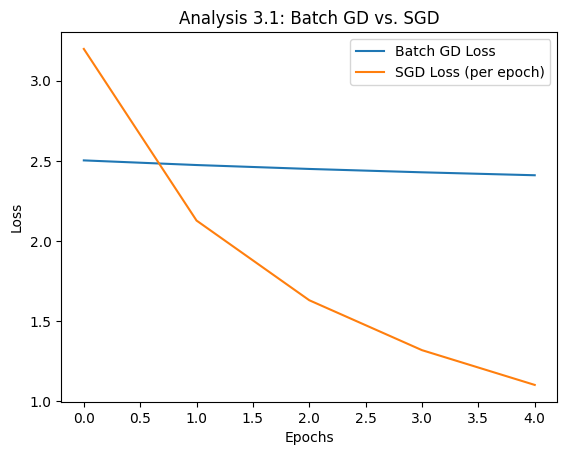

In [45]:
# --- Run Batch GD ---
print("Running Batch Gradient Descent...")
np.random.seed(seed)
H1, H2, H3, H4 = 64, 128, 64, 16 

init_params_batch = Initialization(I_clf, H1, H2, H3, O_clf)

losses_batch, accuracies_batch, parameters_final_batch = training_clf(X_sample_train, y_sample_train, init_params_batch, eta=0.01, num_iters=5, lmbda=0.01)

# --- Run SGD ---
print("Running Stochastic Gradient Descent...")
np.random.seed(seed)

init_params_sgd = Initialization(I_clf, H1, H2, H3, O_clf)

losses_sgd, parameters_final_sgd = training_clf_sgd(X_sample_train, y_sample_train, init_params_sgd, eta=0.01, num_epochs=5, lmbda=0.01)

# --- Plot Results ---
plt.plot(losses_batch, label='Batch GD Loss')
plt.plot(losses_sgd, label='SGD Loss (per epoch)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Analysis 3.1: Batch GD vs. SGD')
plt.show()

### 3.1 Analysis (Written)

in doc


## 3.2 Analysis: Activation Functions (ReLU vs. Sigmoid)

The lecture slides discussed the **Vanishing Gradient** problem, often seen with `sigmoid` functions in deep networks.

**Your Task:**
1.  Implement the `sigmoid` function and its derivative `dsigmoid`.
    $$ \text{sigmoid}(z) = \frac{1}{1 + e^{-z}} $$
    $$ \text{dsigmoid}(z) = \text{sigmoid}(z) \cdot (1 - \text{sigmoid}(z)) $$
2.  Modify your functions to accept an `activation` parameter (either 'relu' or 'sigmoid') for the hidden layers. The output layer should *always* be `softmax`.
3.  Train two models (e.g., 500 iterations): one using 'relu' and one using 'sigmoid' for hidden layers.
4.  **Plot:** Plot the loss curves for both models on the *same* graph.
5.  **Analyze:** In your report, answer:
    * Which activation function led to faster convergence? 
    * Based on the lecture, explain *why* the sigmoid network might learn slower.

In [46]:
def sigmoid(x):
    # START TODO ################ (approx. 1 line)
    return 1 / (1 + np.exp(-x))
    # END TODO ###################

def dsigmoid(x):
    # START TODO ################ (approx. 2 lines)
    s = sigmoid(x)
    return s * (1 - s)
    # END TODO ###################


In [47]:
def feed_forward_flexible(X, params, hidden_activation='relu'):
    '''
    Forward pass with selectable hidden activation (4-layer).
    Layer 4 (Output) is always softmax.
    '''
    W1, b1, W2, b2, W3, b3, W4, b4 = params
    cache = []
    A0 = X

    # Select activation function
    g = relu
    if hidden_activation == 'sigmoid':
        g = sigmoid

    # START TODO ########################

    Z1 = W1 @ A0 + b1
    A1 = g(Z1)

    Z2 = W2 @ A1 + b2
    A2 = g(Z2)

    Z3 = W3 @ A2 + b3
    A3 = g(Z3)

    Z4 = W4 @ A3 + b4
    A4 = softmax(Z4)

    cache = [Z1, A1, Z2, A2, Z3, A3, Z4, A4]

    # END TODO ##########################

    y_out = A4
    return y_out, cache


In [48]:
def Backpropagation_flexible(X, yd, cache, parameters, lmbda, hidden_activation='relu'):
    '''
    Full backward pass with selectable hidden activation (4-layer).
    '''
    # Select derivative function
    dg = drelu
    if hidden_activation == 'sigmoid':
        dg = dsigmoid

    m = X.shape[1]
    W1, b1, W2, b2, W3, b3, W4, b4 = parameters
    Z1, A1, Z2, A2, Z3, A3, Z4, A4 = cache
    grads = {}

    # START TODO ################

    # Layer 4 (Softmax + Cross-Entropy)
    dZ4 = (1 / m) * (A4 - yd)
    dW4 = dZ4 @ A3.T + (lmbda / m) * W4
    db4 = np.sum(dZ4, axis=1, keepdims=True)
    dA3 = W4.T @ dZ4

    # Layer 3 (hidden activation)
    dZ3 = dA3 * dg(Z3)
    dW3 = dZ3 @ A2.T + (lmbda / m) * W3
    db3 = np.sum(dZ3, axis=1, keepdims=True)
    dA2 = W3.T @ dZ3

    # Layer 2 (hidden activation)
    dZ2 = dA2 * dg(Z2)
    dW2 = dZ2 @ A1.T + (lmbda / m) * W2
    db2 = np.sum(dZ2, axis=1, keepdims=True)
    dA1 = W2.T @ dZ2

    # Layer 1 (hidden activation)
    dZ1 = dA1 * dg(Z1)
    dW1 = dZ1 @ X.T + (lmbda / m) * W1
    db1 = np.sum(dZ1, axis=1, keepdims=True)

    grads["dW1"], grads["db1"] = dW1, db1
    grads["dW2"], grads["db2"] = dW2, db2
    grads["dW3"], grads["db3"] = dW3, db3
    grads["dW4"], grads["db4"] = dW4, db4

    # END TODO ###################

    return grads


In [49]:
def training_flexible(X, yd, parameters, eta=0.05, num_iters=3000, lmbda=0.1, hidden_activation='relu'):
    '''
    Trains the classification model with selectable hidden activation (4-layer).
    '''
    losses = []
    m = X.shape[1]
    
    W1, b1, W2, b2, W3, b3, W4, b4 = parameters

    for i in tqdm(range(num_iters)):
        # START TODO ################

        # 1) Forward (hidden layers use relu/sigmoid, output is softmax)
        y_pred, cache = feed_forward_flexible(
            X, [W1, b1, W2, b2, W3, b3, W4, b4],
            hidden_activation=hidden_activation
        )

        # 2) Data loss (Cross-Entropy)
        loss = cross_entropy_loss(y_pred, yd)

        # 3) Regularization loss (L2)
        reg_loss = regularization_L2(lmbda, W1, W2, W3, W4, m)

        # 4) Total loss
        total_loss = loss + reg_loss
        losses.append(total_loss)

        # 5) Backprop (use matching derivative inside)
        grads = Backpropagation_flexible(
            X, yd, cache,
            [W1, b1, W2, b2, W3, b3, W4, b4],
            lmbda,
            hidden_activation=hidden_activation
        )

        # 6) Update parameters
        W1 = W1 - eta * grads["dW1"]
        b1 = b1 - eta * grads["db1"]
        W2 = W2 - eta * grads["dW2"]
        b2 = b2 - eta * grads["db2"]
        W3 = W3 - eta * grads["dW3"]
        b3 = b3 - eta * grads["db3"]
        W4 = W4 - eta * grads["dW4"]
        b4 = b4 - eta * grads["db4"]

        # END TODO ###################
            
    parameters_final = [W1, b1, W2, b2, W3, b3, W4, b4]
    return losses, parameters_final


Running Model with ReLU...
Parameters initialized with He Initialization.


100%|██████████| 500/500 [00:15<00:00, 31.48it/s]


Running Model with Sigmoid...
Parameters initialized with He Initialization.


100%|██████████| 500/500 [00:26<00:00, 18.87it/s]


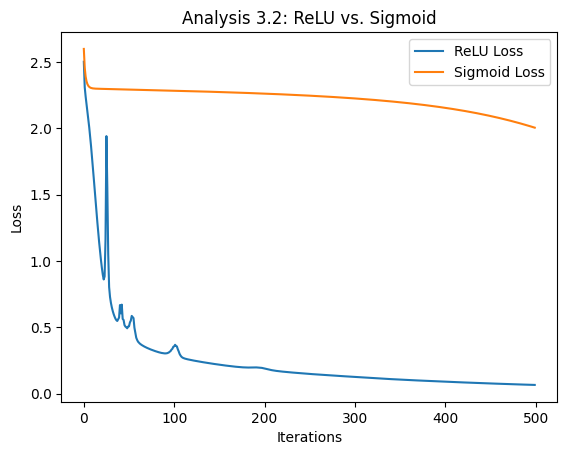

In [50]:
# --- Run ReLU Model --- 
print("Running Model with ReLU...")
np.random.seed(seed)
init_params_relu = Initialization(I_clf, H1, H2, H3, O_clf)
losses_relu, params_relu = training_flexible(X_sample_train, y_sample_train, init_params_relu, 
                                               eta=0.1, num_iters=500, lmbda=0.01, hidden_activation='relu')

# --- Run Sigmoid Model --- 
print("Running Model with Sigmoid...")
np.random.seed(seed)
init_params_sigmoid = Initialization(I_clf, H1, H2, H3, O_clf)
losses_sigmoid, params_sigmoid = training_flexible(X_sample_train, y_sample_train, init_params_sigmoid, 
                                                   eta=0.1, num_iters=500, lmbda=0.01, hidden_activation='sigmoid')

# --- Plot Results --- 
plt.plot(losses_relu, label='ReLU Loss')
plt.plot(losses_sigmoid, label='Sigmoid Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.title('Analysis 3.2: ReLU vs. Sigmoid')
plt.show()

### 3.2 Analysis (Written)

in doc


## 3.3 Analysis: Learning Rate (Eta)

The learning rate ($\eta$ or $\alpha$) is a critical hyperparameter. 

**Your Task:**
1.  Run your `training_clf` function (with ReLU) three times, using the **full training set** (`x_train_clf`, `y_train_clf`) for **100 iterations**.
    * Run 1: $\eta = 1.0$ (High)
    * Run 2: $\eta = 0.1$ (Medium - your baseline)
    * Run 3: $\eta = 0.001$ (Low)
2.  **Plot:** Plot the loss curves for all three runs on the *same* graph.
3.  **Analyze:** In your report, answer:
    * What behavior do you observe for the *high* learning rate? Does it match the "overshooting" concept from the lecture?
    * What behavior do you observe for the *low* learning rate?
    * What does this tell you about the importance of tuning this parameter?

Running LR=1.0 (High)...
Parameters initialized with He Initialization.


100%|██████████| 100/100 [00:27<00:00,  3.61it/s]


Running LR=0.1 (Medium)...
Parameters initialized with He Initialization.


100%|██████████| 100/100 [00:27<00:00,  3.61it/s]


Running LR=0.001 (Low)...
Parameters initialized with He Initialization.


100%|██████████| 100/100 [00:27<00:00,  3.63it/s]


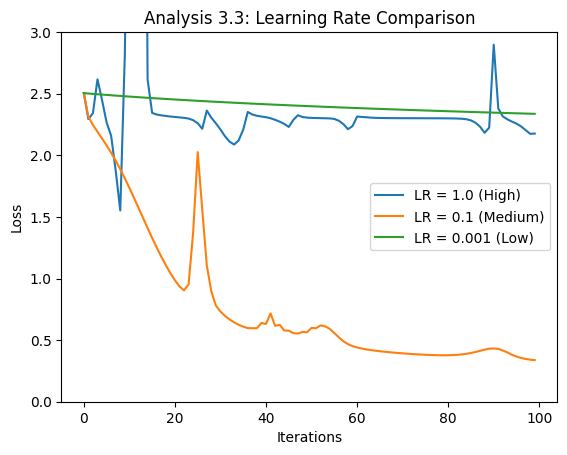

In [51]:
# --- Run LR Analysis --- 
# Note: Using the *full* training set now
print("Running LR=1.0 (High)...")
np.random.seed(seed)
init_params_lr1 = Initialization(I_clf, H1, H2, H3, O_clf)
losses_lr_high, _, _ = training_clf(x_train_clf, y_train_clf, init_params_lr1, eta=1.0, num_iters=100, lmbda=0.01)

print("Running LR=0.1 (Medium)...")
np.random.seed(seed)
init_params_lr2 = Initialization(I_clf, H1, H2, H3, O_clf)
losses_lr_med, _, _ = training_clf(x_train_clf, y_train_clf, init_params_lr2, eta=0.1, num_iters=100, lmbda=0.01)

print("Running LR=0.001 (Low)...")
np.random.seed(seed)
init_params_lr3 = Initialization(I_clf, H1, H2, H3, O_clf)
losses_lr_low, _, _ = training_clf(x_train_clf, y_train_clf, init_params_lr3, eta=0.001, num_iters=100, lmbda=0.01)

# --- Plot Results --- 
plt.plot(losses_lr_high, label='LR = 1.0 (High)')
plt.plot(losses_lr_med, label='LR = 0.1 (Medium)')
plt.plot(losses_lr_low, label='LR = 0.001 (Low)')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.title('Analysis 3.3: Learning Rate Comparison')
plt.ylim(0, 3) # Limit y-axis to see the differences better
plt.show()

### 3.3 Analysis (Written)

in doc

## 3.4 Analysis: Overfitting and Regularization (Lambda)

The lecture slides mentioned **Overfitting** as a key problem in large networks. L2 Regularization (controlled by $\lambda$) is a technique to combat this.

**Your Task:**
1.  Train two models using `training_clf` (with ReLU, $\eta=0.1$) on the **full training set** for 1000 iterations.
    * Run 1: **With Regularization** ($\lambda = 0.1$)
    * Run 2: **Without Regularization** ($\lambda = 0$)
2.  For *each* of the two trained models, calculate and record:
    * The final **Training Accuracy** (on `x_train_clf`).
    * The final **Test Accuracy** (on `x_test_clf`).
3.  **Analyze:** In your report, present these 4 accuracy numbers (e.g., in a small table). 
    * Which model had a *higher* training accuracy? 
    * Which model had a *higher* test accuracy?
    * Did the model without regularization show signs of **overfitting** (a large gap between training and test accuracy)? Explain how L2 regularization helps prevent this.

In [52]:
# --- Run Regularization Analysis --- 
num_iters_reg = 1000
eta_reg = 0.1

print("Running WITH Regularization (lambda=0.1)...")
np.random.seed(seed)
init_params_with_reg = Initialization(I_clf, H1, H2, H3, O_clf)
_, _, params_with_reg = training_clf(x_train_clf, y_train_clf, init_params_with_reg, 
                                      eta=eta_reg, num_iters=num_iters_reg, lmbda=0.1)

print("Running WITHOUT Regularization (lambda=0)...")
np.random.seed(seed)
init_params_no_reg = Initialization(I_clf, H1, H2, H3, O_clf)
_, _, params_no_reg = training_clf(x_train_clf, y_train_clf, init_params_no_reg, 
                                   eta=eta_reg, num_iters=num_iters_reg, lmbda=0)

# --- Calculate Accuracies --- 
print("\nCalculating accuracies...")

# Model WITH Regularization
y_pred_train_with_reg, _ = feed_forward_clf(x_train_clf, params_with_reg)
acc_train_with_reg = accuracy_score(np.argmax(y_train_clf, axis=0), np.argmax(y_pred_train_with_reg, axis=0))
y_pred_test_with_reg, _ = feed_forward_clf(x_test_clf, params_with_reg)
acc_test_with_reg = accuracy_score(np.argmax(y_test_clf, axis=0), np.argmax(y_pred_test_with_reg, axis=0))

# Model WITHOUT Regularization
y_pred_train_no_reg, _ = feed_forward_clf(x_train_clf, params_no_reg)
acc_train_no_reg = accuracy_score(np.argmax(y_train_clf, axis=0), np.argmax(y_pred_train_no_reg, axis=0))
y_pred_test_no_reg, _ = feed_forward_clf(x_test_clf, params_no_reg)
acc_test_no_reg = accuracy_score(np.argmax(y_test_clf, axis=0), np.argmax(y_pred_test_no_reg, axis=0))

print("--- Analysis 3.4 Results ---")
print(f"WITH Regularization (lambda=0.1):")
print(f"  Training Accuracy: {acc_train_with_reg * 100:.2f}%")
print(f"  Test Accuracy:     {acc_test_with_reg * 100:.2f}%")
print(f"  Gap:               {(acc_train_with_reg - acc_test_with_reg) * 100:.2f}%")
print("\nWITHOUT Regularization (lambda=0):")
print(f"  Training Accuracy: {acc_train_no_reg * 100:.2f}%")
print(f"  Test Accuracy:     {acc_test_no_reg * 100:.2f}%")
print(f"  Gap:               {(acc_train_no_reg - acc_test_no_reg) * 100:.2f}%")


Running WITH Regularization (lambda=0.1)...
Parameters initialized with He Initialization.


100%|██████████| 1000/1000 [04:34<00:00,  3.65it/s]


Running WITHOUT Regularization (lambda=0)...
Parameters initialized with He Initialization.


100%|██████████| 1000/1000 [04:43<00:00,  3.52it/s]



Calculating accuracies...
--- Analysis 3.4 Results ---
WITH Regularization (lambda=0.1):
  Training Accuracy: 96.93%
  Test Accuracy:     95.92%
  Gap:               1.01%

WITHOUT Regularization (lambda=0):
  Training Accuracy: 96.93%
  Test Accuracy:     95.93%
  Gap:               1.00%


### 3.4 Analysis (Written)

in doc

## 3.5 Analysis: The Impact of Initialization

In Part 1, you implemented **He Initialization**. Now, let's see why it is so important.

**Your Task:**
1.  Create a modified version of your initialization function (or manually create a params list) where weights are initialized with **very small random numbers** (e.g., `np.random.randn(...) * 0.01`).
2.  Train a model on MNIST for 500 iterations using this "Bad Initialization".
3.  **Compare:** Compare the accuracy curve of this model with your "He Initialization" model.
4.  **Analyze:**
    * Did the model with small weights learn anything? (Is accuracy better than random guessing ~10%?)
    * Explain why this happens using the concept of **Vanishing Gradient**.

100%|██████████| 500/500 [00:07<00:00, 63.66it/s]


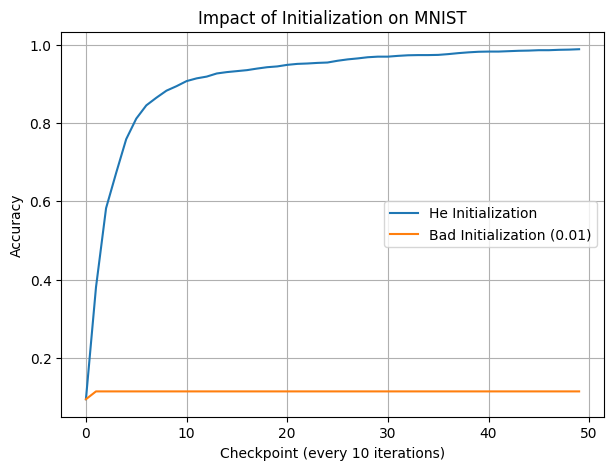

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ================== Initializations ==================

def initialize_parameters_he(layer_dims, seed=42):
    np.random.seed(seed)
    params = []
    for l in range(1, len(layer_dims)):
        W = np.random.randn(layer_dims[l], layer_dims[l-1]) * np.sqrt(2 / layer_dims[l-1])
        b = np.zeros((layer_dims[l], 1))
        params.extend([W, b])
    return params


def initialize_parameters_bad(layer_dims, seed=42):
    np.random.seed(seed)
    params = []
    for l in range(1, len(layer_dims)):
        W = np.random.randn(layer_dims[l], layer_dims[l-1]) * 0.01
        b = np.zeros((layer_dims[l], 1))
        params.extend([W, b])
    return params


# ================== Training with Accuracy ==================

def train_clf_with_accuracy(X, yd, parameters, eta=0.05, num_iters=500, lmbda=0.1):
    accs = []

    W1, b1, W2, b2, W3, b3, W4, b4 = parameters

    for i in tqdm(range(num_iters)):
        # Forward
        y_pred, cache = feed_forward_clf(X, [W1,b1,W2,b2,W3,b3,W4,b4])

        # Backprop
        grads = Backpropagation_clf(
            X, yd, cache,
            [W1,b1,W2,b2,W3,b3,W4,b4],
            lmbda
        )

        # Update
        W1 -= eta * grads["dW1"]; b1 -= eta * grads["db1"]
        W2 -= eta * grads["dW2"]; b2 -= eta * grads["db2"]
        W3 -= eta * grads["dW3"]; b3 -= eta * grads["db3"]
        W4 -= eta * grads["dW4"]; b4 -= eta * grads["db4"]

        # Accuracy every 10 iterations
        if i % 10 == 0:
            preds = np.argmax(y_pred, axis=0)
            true = np.argmax(yd, axis=0)
            accs.append(np.mean(preds == true))

    return accs


# ================== Run Experiment (FIXED) ==================

# توی نوت‌بوک خودت، MNIST این‌هاست:
# x_train_clf: (784, N)   y_train_clf: (10, N)
X = x_train_clf
yd = y_train_clf

# فقط 2000 نمونه اول
X_small = X[:, :2000]
yd_small = yd[:, :2000]

layer_dims = [X_small.shape[0], 128, 64, 32, yd_small.shape[0]]

# He Initialization
params_he = initialize_parameters_he(layer_dims)
acc_he = train_clf_with_accuracy(X_small, yd_small, params_he)

# Bad Initialization
params_bad = initialize_parameters_bad(layer_dims)
acc_bad = train_clf_with_accuracy(X_small, yd_small, params_bad)


# ================== Plot ==================

plt.figure(figsize=(7,5))
plt.plot(acc_he, label="He Initialization")
plt.plot(acc_bad, label="Bad Initialization (0.01)")
plt.xlabel("Checkpoint (every 10 iterations)")
plt.ylabel("Accuracy")
plt.title("Impact of Initialization on MNIST")
plt.legend()
plt.grid(True)
plt.show()
